In [1]:
import sys, subprocess, importlib


for pkg in ["pandas", "matplotlib", "seaborn", "scipy"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg])

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import Markdown, display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLOR = "steelblue"


SALES_FILE = None

def find_file(name):
    """Look in the notebook folder, Downloads, and Desktop (also catches 'name (1).csv')."""
    stem, ext = os.path.splitext(name)
    folders = [os.getcwd(), os.path.expanduser("~/Downloads"), os.path.expanduser("~/Desktop")]
    for folder in folders:
        exact = os.path.join(folder, name)
        if os.path.exists(exact):
            return exact
        matches = sorted(glob.glob(os.path.join(folder, f"{stem}*{ext}")))
        if matches:
            return matches[0]
    return None

print("Notebook folder:", os.getcwd())

Notebook folder: /Users/ray


In [2]:
path = find_file("chickwts.csv")
if path is None:
   
    path = "https://vincentarelbundock.github.io/Rdatasets/csv/datasets/chickwts.csv"
    print("chickwts.csv not found locally, using public copy of the dataset.")
chick = pd.read_csv(path)
print("Loaded:", path)

feed_means = chick.groupby("feed")["weight"].mean().sort_values(ascending=False)
print()
print(feed_means.round(1))
print(f"\nHighest: {feed_means.idxmax()} | Lowest: {feed_means.idxmin()} | Feeds: {len(feed_means)}")

Loaded: /Users/ray/chickwts.csv

feed
sunflower    328.9
casein       323.6
meatmeal     276.9
soybean      246.4
linseed      218.8
horsebean    160.2
Name: weight, dtype: float64

Highest: sunflower | Lowest: horsebean | Feeds: 6


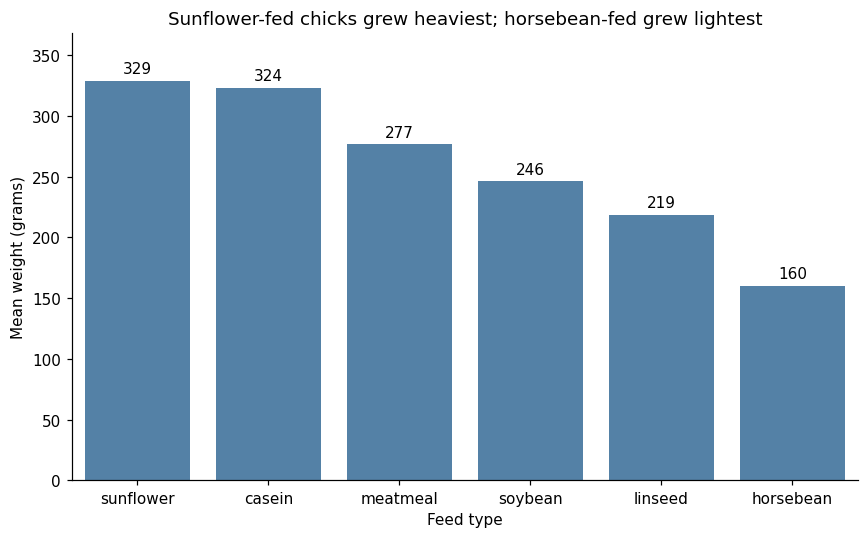

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=feed_means.index, y=feed_means.values, color=COLOR, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_title(f"{feed_means.idxmax().capitalize()}-fed chicks grew heaviest; {feed_means.idxmin()}-fed grew lightest")
ax.set_xlabel("Feed type")
ax.set_ylabel("Mean weight (grams)")
ax.set_ylim(0, feed_means.max() * 1.12)
plt.tight_layout()
plt.show()

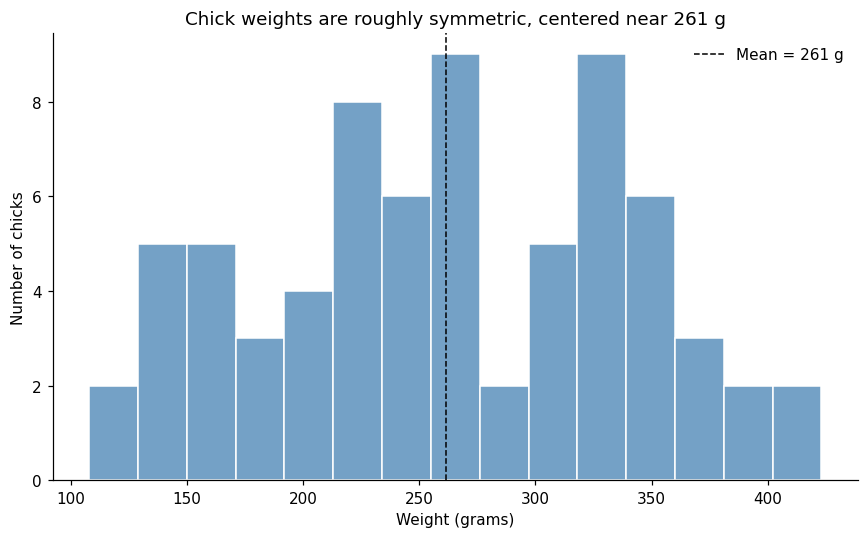

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=chick, x="weight", bins=15, color=COLOR, edgecolor="white", ax=ax)
ax.axvline(chick["weight"].mean(), color="black", linestyle="--", linewidth=1,
           label=f"Mean = {chick['weight'].mean():.0f} g")
ax.set_title(f"Chick weights are roughly symmetric, centered near {chick['weight'].mean():.0f} g")
ax.set_xlabel("Weight (grams)")
ax.set_ylabel("Number of chicks")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [5]:
mpath = find_file("museum_visitors.csv")
if mpath is None:
    raise FileNotFoundError(
        "museum_visitors.csv not found. Download it and put it in this folder:\n"
        f"  {os.getcwd()}\n(Downloads and Desktop were also checked.)")
museum = pd.read_csv(mpath)
print("Loaded:", mpath)
display(museum.head())


date_col = next((c for c in museum.columns if c.strip().lower() in ("date", "month", "year", "time", "period")), None)
if date_col is None:
    for c in museum.columns:
        if museum[c].dtype == object and pd.to_datetime(museum[c], errors="coerce").notna().mean() > 0.9:
            date_col = c
            break
if date_col is None:
    date_col = museum.columns[0]

museum[date_col] = pd.to_datetime(museum[date_col], errors="coerce")
museum = museum.dropna(subset=[date_col]).sort_values(date_col)
value_cols = [c for c in museum.select_dtypes("number").columns if c != date_col]
print(f"Date column: {date_col!r} | Visitor columns: {value_cols}")

Loaded: /Users/ray/museum_visitors.csv


,Date,Avila Adobe,Firehouse Museum,Chinese American Museum,America Tropical Interpretive Center
0,2014-01-01,24778,4486,1581,6602
1,2014-02-01,18976,4172,1785,5029
2,2014-03-01,25231,7082,3229,8129
3,2014-04-01,26989,6756,2129,2824
4,2014-05-01,36883,10858,3676,10694


Date column: 'Date' | Visitor columns: ['Avila Adobe', 'Firehouse Museum', 'Chinese American Museum', 'America Tropical Interpretive Center']


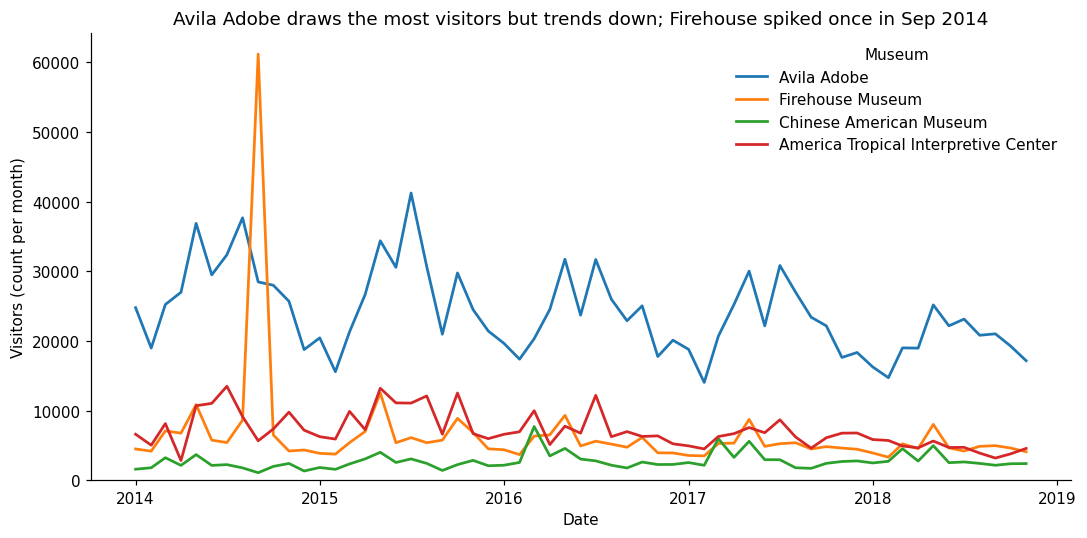

**Trend:** Avila Adobe's average monthly visitors went down from **27,776** in 2014 to **22,526** in 2017. (The one-month Firehouse Museum spike in Sep 2014 is an outlier, not a trend.)

In [6]:
museum_long = museum.melt(id_vars=date_col, value_vars=value_cols,
                          var_name="Museum", value_name="Visitors")

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=museum_long, x=date_col, y="Visitors",
             hue="Museum" if len(value_cols) > 1 else None,
             estimator=None, linewidth=1.8, ax=ax)
if len(value_cols) > 1:
    ax.legend(title="Museum", frameon=False)


avila = museum.set_index(date_col)["Avila Adobe"]
yearly = avila.groupby(avila.index.year).mean()   # 2014-2017 are full years
first, last = yearly.loc[2014], yearly.loc[2017]
direction = "down" if last < first else "up"

ax.set_title(f"Avila Adobe draws the most visitors but trends {direction}; Firehouse spiked once in Sep 2014")
ax.set_xlabel("Date")
ax.set_ylabel("Visitors (count per month)")
ax.set_ylim(0)
plt.tight_layout()
plt.show()

display(Markdown(
    f"**Trend:** Avila Adobe's average monthly visitors went {direction} from "
    f"**{first:,.0f}** in 2014 to **{last:,.0f}** in 2017. "
    f"(The one-month Firehouse Museum spike in Sep 2014 is an outlier, not a trend.)"))

In [7]:
spath = find_file(SALES_FILE) if SALES_FILE else None
if spath is None:
    for folder in (os.getcwd(), os.path.expanduser("~/Downloads"), os.path.expanduser("~/Desktop")):
        hits = sorted(glob.glob(os.path.join(folder, "*clean*.csv")))
        if hits:
            spath = hits[0]
            break
if spath is not None:
    sales = pd.read_csv(spath)
    print("Loaded cleaned file:", spath)
else:
    spath = find_file("messy_sales.csv")
    if spath is None:
        raise FileNotFoundError("Put your cleaned Module 4 sales CSV in the notebook folder "
                                "and set SALES_FILE = 'yourfile.csv' in the Setup cell.")
    sales = pd.read_csv(spath)
    sales = sales.dropna(subset=["price", "qty"]).drop_duplicates()
    sales["date"] = pd.to_datetime(sales["date"], format="mixed", errors="coerce")
    print("No cleaned file found; cleaned", spath, "in the notebook (edit to match Lab 4).")

sales["revenue"] = sales["price"] * sales["qty"]
print(sales.shape, "| missing prices:", sales["price"].isna().sum())
display(sales.head())

Loaded cleaned file: /Users/ray/sales_clean.csv
(292, 7) | missing prices: 0


,order_id,date,product,price,qty,zip,revenue
0,1254,2026-04-06,mug,11.36,4,60614,45.44
1,1057,2026-05-30,charger,14.79,3,30303,44.37
2,1150,2026-05-06,mug,5.50,1,10001,5.50
3,1066,2026-05-30,notebook,37.53,1,98101,37.53
4,1114,2026-04-06,webcam,45.59,4,90405,182.36


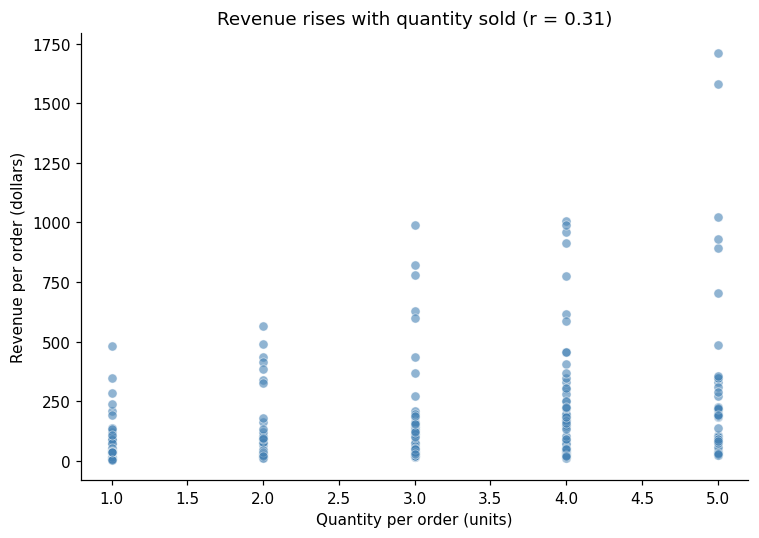

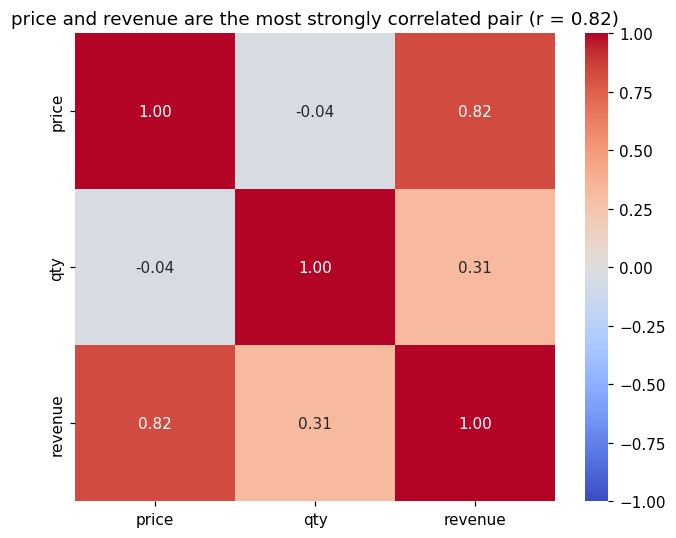

**Strongest off-diagonal correlation:** `price` and `revenue`, r = **0.82**.

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=sales, x="qty", y="revenue", alpha=0.6, color=COLOR, ax=ax)
r_qr = sales["qty"].corr(sales["revenue"])
ax.set_title(f"Revenue {'rises' if r_qr > 0 else 'falls'} with quantity sold (r = {r_qr:.2f})")
ax.set_xlabel("Quantity per order (units)")
ax.set_ylabel("Revenue per order (dollars)")
plt.tight_layout()
plt.show()

corr = sales.drop(columns=["order_id", "zip"], errors="ignore").corr(numeric_only=True)
pairs = corr.where(~np.eye(len(corr), dtype=bool)).abs().stack()
a, b = pairs.idxmax()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title(f"{a} and {b} are the most strongly correlated pair (r = {corr.loc[a, b]:.2f})")
plt.tight_layout()
plt.show()

display(Markdown(f"**Strongest off-diagonal correlation:** `{a}` and `{b}`, r = **{corr.loc[a, b]:.2f}**."))

### Step 6: Null hypothesis

**H₀:** The mean weight of sunflower-fed and horsebean-fed chicks will be the same(μ_sunflower = μ_horsebean).

In [9]:
sun = chick.loc[chick["feed"] == "sunflower", "weight"]
horse = chick.loc[chick["feed"] == "horsebean", "weight"]

t_stat, p_val = stats.ttest_ind(sun, horse)  
diff = sun.mean() - horse.mean()

print(f"Sunflower: n = {len(sun)}, mean = {sun.mean():.1f} g")
print(f"Horsebean: n = {len(horse)}, mean = {horse.mean():.1f} g")
print(f"Difference = {diff:.1f} g | t = {t_stat:.2f} | p = {p_val:.2e}")

Sunflower: n = 12, mean = 328.9 g
Horsebean: n = 10, mean = 160.2 g
Difference = 168.7 g | t = 8.85 | p = 2.37e-08


### Step 8: Conclusion

On average sunflower-fed chicks weighed 168.7 g more than horsebean-fed chicks with a very low p-score of 2.4e-08 so I reject the null hypothesis, but with limited data(only 12 and 10 chicks from a single farm), this may not generalize to other flocks.

### Step 9: Honest-chart audit
On the feed bar chart, the y-axis starts at zero (`set_ylim(0, ...)`) so bar heights are proportional to the real means and the y-axis is labeled in units ("Mean weight (grams)").

## Appendix: AI Use Disclosure

**Tool used:** Claude

**What I used it for:** Chart syntax and code help (seaborn/matplotlib formatting, loading files, running the t-test).
**Key prompts:**
1. "how seaborn bar chart of mean chick weight by feed, sorted, with value labels and a y-axis in g?"
2. "line chart of museum visitors over time for several museums?"
3. "How to make a correlation heatmap with annotations and find the strongest off-diagonal pair?"
4. "how to do ttest_ind on two feed groups and print the difference in means?"

I ran every cell top to bottom and confirmed that the results match the lab's expected checkpoints